# Book Recommendation System

This project explores three approaches to recommending books using
book metadata and user ratings from the Goodbooks-10k dataset.

## Approaches

1. **Popularity-Based Ranking** - ranks books using a weighted rating.
2. **Content-Based Filtering** - recommends books using similarities
   between authors and titles.
3. **Collaborative Filtering** - uses user-rating patterns and
   dimensionality reduction to identify similar books.

## Project Goal

The goal is to compare different recommendation strategies and
understand their strengths and limitations.

> This is an exploratory project. The example recommendations are
> inspected qualitatively; they are not a formal evaluation of
> recommendation quality.

## 1. Imports and Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

## 2. Load Data

In [2]:
books = pd.read_csv("books.csv")
ratings = pd.read_csv("ratings.csv")

print(f"Books dataset shape: {books.shape}")
print(f"Ratings dataset shape: {ratings.shape}")
print(f"Unique users: {ratings['user_id'].nunique():,}")
print(f"Unique rated books: {ratings['book_id'].nunique():,}")

print("\nSelected book metadata:")
display(
    books[
        ["id", "title", "authors", "average_rating", "ratings_count"]
    ].head()
)

print("\nSample user ratings:")
display(ratings.head())

Books dataset shape: (10000, 23)
Ratings dataset shape: (981756, 3)
Unique users: 53,424
Unique rated books: 10,000

Selected book metadata:


,id,title,authors,average_rating,ratings_count
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34,4780653
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44,4602479
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3.57,3866839
3,4,To Kill a Mockingbird,Harper Lee,4.25,3198671
4,5,The Great Gatsby,F. Scott Fitzgerald,3.89,2683664



Sample user ratings:


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


## 3. Exploratory Data Analysis and Cleaning

Before building recommenders, I inspect the distribution of user ratings
and check the metadata required by the models.

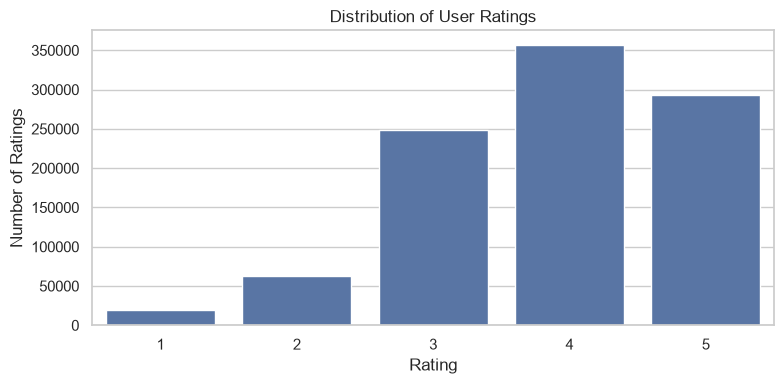

Missing values in selected book metadata:


,missing_values
title,0
authors,0
original_title,585


Valid ratings after cleaning: 981,756


In [3]:
plt.figure(figsize=(8, 4))
sns.countplot(data=ratings, x="rating")

plt.title("Distribution of User Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()


metadata_columns = ["title", "authors", "original_title"]

print("Missing values in selected book metadata:")
display(
    books[metadata_columns]
    .isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)


books["title"] = books["title"].fillna("").astype(str)
books["authors"] = books["authors"].fillna("Unknown").astype(str)

books["original_title"] = (
    books["original_title"]
    .fillna(books["title"])
    .astype(str)
)


ratings = ratings.copy()

for column in ["user_id", "book_id", "rating"]:
    ratings[column] = pd.to_numeric(
        ratings[column],
        errors="coerce"
    )

ratings = ratings.dropna(
    subset=["user_id", "book_id", "rating"]
).copy()

ratings = ratings.loc[
    ratings["rating"].between(1, 5)
].copy()

ratings["user_id"] = ratings["user_id"].astype("int64")
ratings["book_id"] = ratings["book_id"].astype("int64")
ratings["rating"] = ratings["rating"].astype("int8")

print(f"Valid ratings after cleaning: {len(ratings):,}")

## 4. Popularity-Based Recommender

A popularity-based recommender provides a simple baseline.

Instead of ranking books only by their average rating, I use a weighted
rating that accounts for the number of ratings a book has received.
This reduces the influence of books with very few ratings.

The calculation uses summary statistics provided in the books metadata.

In [4]:
popularity_data = books.copy()

popularity_data["average_rating"] = pd.to_numeric(
    popularity_data["average_rating"],
    errors="coerce"
)

popularity_data["ratings_count"] = pd.to_numeric(
    popularity_data["ratings_count"],
    errors="coerce"
)

popularity_data = popularity_data.dropna(
    subset=["average_rating", "ratings_count"]
).copy()


# R: average rating of a book
R = popularity_data["average_rating"]

# v: number of ratings for a book
v = popularity_data["ratings_count"]

# C: mean rating across books
C = R.mean()

# m: minimum vote threshold, set to the 95th percentile
m = v.quantile(0.95)

qualified_books = popularity_data.loc[
    popularity_data["ratings_count"] >= m
].copy()

v = qualified_books["ratings_count"]
R = qualified_books["average_rating"]

qualified_books["weighted_rating"] = (
    (v / (v + m)) * R
    + (m / (v + m)) * C
)

top_popular = qualified_books.sort_values(
    "weighted_rating",
    ascending=False
)

print("Top 10 Books by Weighted Rating:")
display(
    top_popular[
        ["title", "authors", "average_rating",
         "ratings_count", "weighted_rating"]
    ].head(10)
)

Top 10 Books by Weighted Rating:


,title,authors,average_rating,ratings_count,weighted_rating
24,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",4.61,1746574,4.555956
26,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",4.54,1678823,4.490428
17,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",4.53,1832823,4.485090
23,Harry Potter and the Goblet of Fire (Harry Pot...,"J.K. Rowling, Mary GrandPré",4.53,1753043,4.483227
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44,4602479,4.424365
20,Harry Potter and the Order of the Phoenix (Har...,"J.K. Rowling, Mary GrandPré",4.46,1735368,4.419054
30,The Help,Kathryn Stockett,4.45,1531753,4.405158
38,"A Game of Thrones (A Song of Ice and Fire, #1)",George R.R. Martin,4.45,1319204,4.398759
134,"A Storm of Swords (A Song of Ice and Fire, #3)",George R.R. Martin,4.54,469022,4.396645
421,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,4.74,190050,4.391147


## 5. Content-Based Filtering

Content-based filtering recommends books using their metadata.

In this project, each book is represented by a text description built
from its author and original title. TF-IDF converts these descriptions
into numerical vectors that can be compared using cosine distance.

This approach can recommend books with similar metadata, even when
user-rating information is limited.

In [5]:
books["content"] = (
    books["authors"].fillna("").astype(str)
    + " "
    + books["original_title"].fillna("").astype(str)
).str.strip()

tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(books["content"])

print(f"Number of books: {tfidf_matrix.shape[0]:,}")
print(f"Number of TF-IDF features: {tfidf_matrix.shape[1]:,}")
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")

Number of books: 10,000
Number of TF-IDF features: 14,654
TF-IDF matrix shape: (10000, 14654)


In [6]:
content_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11
)

content_model.fit(tfidf_matrix)


def get_content_recommendations(title, n_recommendations=10):
    if not isinstance(title, str) or not title.strip():
        return pd.DataFrame(
            columns=["title", "authors", "similarity"]
        )

    matches = books.index[
        books["title"].str.casefold() == title.casefold()
    ]

    if len(matches) == 0:
        print(f"Book not found: {title}")
        return pd.DataFrame(
            columns=["title", "authors", "similarity"]
        )

    book_idx = matches[0]

    n_neighbors = min(
        n_recommendations + 1,
        len(books)
    )

    distances, indices = content_model.kneighbors(
        tfidf_matrix[book_idx],
        n_neighbors=n_neighbors
    )

    recommendations = []

    for distance, neighbor_idx in zip(
        distances[0], indices[0]
    ):
        if neighbor_idx == book_idx:
            continue

        book = books.iloc[neighbor_idx]

        recommendations.append({
            "title": book["title"],
            "authors": book["authors"],
            "similarity": round(float(1 - distance), 3)
        })

        if len(recommendations) >= n_recommendations:
            break

    return pd.DataFrame(recommendations)

### Example Content-Based Recommendations

The following examples illustrate how metadata similarity influences
the recommended books.

In [8]:
test_books = [
    "The Hobbit",
    "Paper Towns"
]

for test_book in test_books:
    print(f"\nRecommendations for: {test_book}")
    display(
        get_content_recommendations(
            test_book,
            n_recommendations=10
        )
    )


Recommendations for: The Hobbit


,title,authors,similarity
0,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...,J.R.R. Tolkien,0.738
1,"The History of the Hobbit, Part One: Mr. Baggins","John D. Rateliff, J.R.R. Tolkien",0.564
2,The Hobbit: Graphic Novel,"Chuck Dixon, J.R.R. Tolkien, David Wenzel, Sea...",0.501
3,The Children of Húrin,"J.R.R. Tolkien, Christopher Tolkien, Alan Lee",0.463
4,The Silmarillion (Middle-Earth Universe),"J.R.R. Tolkien, Christopher Tolkien, Ted Nasmith",0.452
5,"The Two Towers (The Lord of the Rings, #2)",J.R.R. Tolkien,0.441
6,"The Return of the King (The Lord of the Rings,...",J.R.R. Tolkien,0.427
7,Unfinished Tales of Númenor and Middle-Earth,"J.R.R. Tolkien, Christopher Tolkien",0.413
8,"The Lord of the Rings (The Lord of the Rings, ...",J.R.R. Tolkien,0.391
9,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,0.353



Recommendations for: Paper Towns


,title,authors,similarity
0,The Fault in Our Stars,John Green,0.283
1,Looking for Alaska,John Green,0.276
2,The Matlock Paper,Robert Ludlum,0.270
3,The Paper Magician (The Paper Magician Trilogy...,Charlie N. Holmberg,0.270
4,An Abundance of Katherines,John Green,0.269
5,The Other Woman,Jane Green,0.242
6,"Darth Paper Strikes Back (Origami Yoda, #2)",Tom Angleberger,0.232
7,To Have and to Hold,Jane Green,0.219
8,The Green Mile,Stephen King,0.217
9,"Green: The Beginning and the End (The Circle, #0)",Ted Dekker,0.217


## 6. Collaborative Filtering with SVD

Collaborative filtering uses user-rating patterns rather than only book
metadata.

The ratings are represented as a sparse book-user matrix. Truncated
SVD then learns a lower-dimensional representation of books based on
rating patterns.

Books with similar representations can be recommended to one another.

In [9]:
ratings_cf = (
    ratings
    .groupby(["user_id", "book_id"], as_index=False)["rating"]
    .mean()
)

user_ids = pd.Index(
    ratings_cf["user_id"].unique(),
    name="user_id"
)

book_ids = pd.Index(
    ratings_cf["book_id"].unique(),
    name="book_id"
)

user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

book_to_idx = {
    book_id: idx
    for idx, book_id in enumerate(book_ids)
}

row_idx = (
    ratings_cf["book_id"]
    .map(book_to_idx)
    .to_numpy(dtype=np.int32)
)

col_idx = (
    ratings_cf["user_id"]
    .map(user_to_idx)
    .to_numpy(dtype=np.int32)
)

rating_values = ratings_cf["rating"].to_numpy(
    dtype=np.float32
)

item_user_matrix = csr_matrix(
    (
        rating_values,
        (row_idx, col_idx)
    ),
    shape=(len(book_ids), len(user_ids)),
    dtype=np.float32
)

density = (
    item_user_matrix.nnz
    / (item_user_matrix.shape[0] * item_user_matrix.shape[1])
)

print(f"Users: {len(user_ids):,}")
print(f"Rated books: {len(book_ids):,}")
print(f"Unique user-book ratings: {item_user_matrix.nnz:,}")
print(f"Matrix shape: {item_user_matrix.shape}")
print(f"Percentage of zero entries: {(1 - density) * 100:.4f}%")

Users: 53,424
Rated books: 10,000
Unique user-book ratings: 979,478
Matrix shape: (10000, 53424)
Percentage of zero entries: 99.8167%


### SVD-Based Book Representations

Truncated SVD maps the sparse rating matrix into a lower-dimensional
representation of books.

The model is fitted once and reused for subsequent recommendation
queries. This avoids repeating the factorization every time a user
requests recommendations for a different book.

In [10]:
n_components = min(
    50,
    item_user_matrix.shape[0] - 1,
    item_user_matrix.shape[1] - 1
)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=RANDOM_STATE
)

item_factors = svd.fit_transform(item_user_matrix)

cf_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

cf_model.fit(item_factors)

print(f"Number of SVD components: {n_components}")
print(f"Book-factor matrix shape: {item_factors.shape}")
print(
    "Explained variance ratio sum: "
    f"{svd.explained_variance_ratio_.sum():.3f}"
)

Number of SVD components: 50
Book-factor matrix shape: (10000, 50)
Explained variance ratio sum: 0.092


### Collaborative Recommendation Function

The function below finds books with similar SVD-based representations.

Unlike content-based filtering, the similarity is derived from
user-rating patterns, not from author names or titles.

In [11]:
def get_collaborative_recommendations(
    book_title,
    n_recommendations=10
):
    if not isinstance(book_title, str) or not book_title.strip():
        return pd.DataFrame(
            columns=["title", "authors", "similarity"]
        )

    matches = books.loc[
        books["title"].str.casefold() == book_title.casefold(),
        "id"
    ]

    if matches.empty:
        print(f"Book not found: {book_title}")
        return pd.DataFrame(
            columns=["title", "authors", "similarity"]
        )

    book_id = matches.iloc[0]

    if book_id not in book_to_idx:
        print(f"No rating data found for: {book_title}")
        return pd.DataFrame(
            columns=["title", "authors", "similarity"]
        )

    book_idx = book_to_idx[book_id]

    n_neighbors = min(
        n_recommendations + 1,
        len(book_ids)
    )

    distances, neighbor_indices = cf_model.kneighbors(
        item_factors[book_idx].reshape(1, -1),
        n_neighbors=n_neighbors
    )

    recommendations = []

    for distance, neighbor_idx in zip(
        distances[0], neighbor_indices[0]
    ):
        if neighbor_idx == book_idx:
            continue

        recommended_book_id = book_ids[neighbor_idx]

        recommended_book = books.loc[
            books["id"] == recommended_book_id,
            ["title", "authors"]
        ]

        if recommended_book.empty:
            continue

        book = recommended_book.iloc[0]

        recommendations.append({
            "title": book["title"],
            "authors": book["authors"],
            "similarity": round(float(1 - distance), 3)
        })

        if len(recommendations) >= n_recommendations:
            break

    return pd.DataFrame(recommendations)

### Example Collaborative Recommendations

The examples below illustrate recommendations based on patterns in
user ratings.

In [12]:
target_book = "The World of the Hunger Games (Hunger Games Trilogy)"

print(f"Collaborative recommendations for: {target_book}")

display(
    get_collaborative_recommendations(
        target_book,
        n_recommendations=10
    )
)

Collaborative recommendations for: The World of the Hunger Games (Hunger Games Trilogy)


,title,authors,similarity
0,"Twilight and Philosophy: Vampires, Vegetarians...","Rebecca Housel, J. Jeremy Wisnewski, William I...",0.976
1,"Twilight: The Graphic Novel, Vol. 2 (Twilight...","Stephenie Meyer, Young Kim",0.942
2,The Ripper (The Vampire Diaries: Stefan's Diar...,"L.J. Smith, Kevin Williamson, Julie Plec",0.933
3,Eclipse: The Complete Illustrated Movie Compan...,Mark Cotta Vaz,0.921
4,Bloodlust (The Vampire Diaries: Stefan's Diari...,"L.J. Smith, Kevin Williamson, Julie Plec",0.897
5,City of Bones / City of Ashes / City of Glass ...,Cassandra Clare,0.894
6,The Hunger Games Tribute Guide,Emily Seife,0.894
7,Love You to Death: The Unofficial Companion to...,Crissy Calhoun,0.893
8,Twilight and History,Nancy Reagin,0.883
9,Marked / Betrayed / Chosen / Untamed (House of...,"P.C. Cast, Kristin Cast",0.866


## 7. Conclusion

This project explores three approaches to book recommendation.

### Main Takeaways

- **Popularity-based ranking** provides a simple baseline based on
  rating summaries and the number of ratings.
- **Content-based filtering** recommends books with similar metadata,
  in this project using authors and original titles.
- **Collaborative filtering** uses user-rating patterns and an SVD-based
  representation to find books that are similar in latent space.

### Limitations

- The content-based model uses a limited set of metadata features.
  It does not currently include tags, genres, or full book descriptions.
- The recommendation examples are inspected qualitatively.
  A separate offline evaluation using held-out ratings and ranking
  metrics has not yet been implemented.
- Recommendations depend on the version and coverage of the dataset.
- The collaborative model requires rating data for the queried book.

### Possible Next Steps

- Evaluate recommendation quality using a held-out test set and
  ranking metrics such as Precision@K or Recall@K.
- Experiment with additional book metadata, such as tags and genres.
- Compare alternative latent-factor dimensions and similarity methods.